In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [8]:
data = pd.read_csv(r"C:\Users\shiva kumar\Downloads\train-test.csv")

data.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [10]:
validation = pd.read_csv(r"C:\Users\shiva kumar\Downloads\validation.csv")

template = pd.read_csv(
    r"C:\Users\shiva kumar\Downloads\validation-predictions-template.csv"
)

december = pd.read_csv(
    r"C:\Users\shiva kumar\Downloads\december-chart-inputs.csv"
)

In [11]:
data.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [12]:
data.tail()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
47995,TR-047996,Reno,Baton Rouge,39.54838,-118.64843,30.50134,-92.65374,1830.9,Flatbed,31786.0,2025-10-31,0.98865,2.05626,3787.32
47996,TR-047997,Greensboro,Memphis,35.98195,-82.78379,35.56802,-89.52871,445.8,Reefer,37465.0,2025-10-31,1.03034,1.51985,1171.93
47997,TR-047998,Greensboro,Cincinnati,35.98195,-82.78379,37.15706,-86.77499,267.9,Flatbed,24528.0,2025-10-31,1.00846,1.46954,713.36
47998,TR-047999,Memphis,Reno,35.56802,-89.52871,39.54838,-118.64843,1901.3,Flatbed,37581.0,2025-10-31,1.00014,2.05132,3987.46
47999,TR-048000,Bakersfield,Baltimore,33.28832,-116.67935,38.16908,-72.74564,2860.4,Dry Van,28359.0,2025-10-31,1.07073,2.31578,5264.84


In [13]:
data.shape

(48000, 14)

In [14]:
data.columns

Index(['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon',
       'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight',
       'date', 'market_index', 'quote_signal', 'posted_rate'],
      dtype='object')

In [15]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


In [16]:
data.describe()

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,47700.000000,47626.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31028.844004,1.083387,2.062468,2373.980682
std,4.315285,13.482431,4.317199,13.476589,728.564416,9391.440620,0.168091,0.291391,1486.493245
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,-47500.000000,0.676390,0.692280,57.220000
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25800.000000,0.949670,1.891030,1251.555000
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31436.500000,1.055800,2.055750,2030.760000
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,1.219590,2.221685,3330.750000
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,1.467780,3.610350,25533.000000


In [17]:
print("Training data:", data.shape)
print("Validation data:", validation.shape)
print("Prediction template:", template.shape)
print("December data:", december.shape)

Training data: (48000, 14)
Validation data: (12000, 13)
Prediction template: (12000, 2)
December data: (31, 7)


In [18]:
# Check missing values in the training dataset

data.isnull().sum()

load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64

In [19]:
missing_values = data.isnull().sum()

missing_values[missing_values > 0]

weight          300
market_index    374
dtype: int64

In [20]:
missing_percentage = (
    data.isnull().mean() * 100
).round(2)

missing_percentage[missing_percentage > 0]

weight          0.62
market_index    0.78
dtype: float64

In [21]:
# Check duplicate rows

data.duplicated().sum()

np.int64(0)

In [23]:
# Check data types of all columns

data.dtypes

load_id          object
pickup           object
delivery         object
pickup_lat      float64
pickup_lon      float64
delivery_lat    float64
delivery_lon    float64
distance        float64
equipment        object
weight          float64
date             object
market_index    float64
quote_signal    float64
posted_rate     float64
dtype: object

In [24]:
data["date"] = pd.to_datetime(
    data["date"], errors="coerce"
)

data["date"].dtype

dtype('<M8[ns]')

In [25]:
# Count invalid dates

data["date"].isna().sum()

np.int64(0)

In [27]:
# Check missing target values

data["posted_rate"].isna().sum()

np.int64(0)

In [28]:
# Unique delivery locations

data["delivery"].nunique()

64

In [29]:
# Unique equipment types

data["equipment"].unique()

array(['Dry Van', 'Reefer', 'Flatbed'], dtype=object)

In [30]:
# Frequency of each equipment type

data["equipment"].value_counts(dropna=False)

equipment
Dry Van    27202
Reefer     12045
Flatbed     8753
Name: count, dtype: int64

In [31]:
# Select numerical columns

numerical_columns = data.select_dtypes(
    include=np.number
).columns

# Calculate IQR bounds for each numerical column

for column in numerical_columns:
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ).sum()

    print(f"{column}: {outliers} potential outliers")

pickup_lat: 0 potential outliers
pickup_lon: 453 potential outliers
delivery_lat: 0 potential outliers
delivery_lon: 467 potential outliers
distance: 32 potential outliers
weight: 424 potential outliers
market_index: 0 potential outliers
quote_signal: 1956 potential outliers
posted_rate: 260 potential outliers


In [32]:
# Missing values in validation data

validation.isnull().sum()

load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          165
date              0
market_index    249
quote_signal      0
dtype: int64

In [33]:
# Duplicate load IDs in validation data

validation["load_id"].duplicated().sum()

np.int64(0)

In [34]:
# Check the prediction template

print(template.columns.tolist())
print("Template rows:", len(template))
print("Unique IDs:", template["load_id"].nunique())

['load_id', 'predicted_rate']
Template rows: 12000
Unique IDs: 12000


In [35]:
data["date"] = pd.to_datetime(
    data["date"],
    errors="coerce"
)

validation["date"] = pd.to_datetime(
    validation["date"],
    errors="coerce"
)

In [36]:
print("Invalid training dates:", data["date"].isna().sum())
print("Invalid validation dates:", validation["date"].isna().sum())

Invalid training dates: 0
Invalid validation dates: 0


In [37]:
numeric_columns = [
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "distance",
    "weight",
    "market_index",
    "quote_signal",
    "posted_rate"
]

print("Negative distances:", (data["distance"] < 0).sum())
print("Non-positive rates:", (data["posted_rate"] <= 0).sum())
print("Zero weights:", (data["weight"] == 0).sum())

print("\nNumerical summary:")
print(data[numeric_columns].describe().T)

Negative distances: 0
Non-positive rates: 0
Zero weights: 0

Numerical summary:
                count          mean          std          min          25%  \
pickup_lat    48000.0     35.647545     4.315285     28.35765     31.98691   
pickup_lon    48000.0    -90.928964    13.482431   -121.69849    -98.40059   
delivery_lat  48000.0     35.641175     4.317199     28.35765     31.98691   
delivery_lon  48000.0    -90.857310    13.476589   -121.69849    -98.40059   
distance      48000.0   1135.856654   728.564416     70.00000    550.40000   
weight        47700.0  31028.844004  9391.440620 -47500.00000  25800.00000   
market_index  47626.0      1.083387     0.168091      0.67639      0.94967   
quote_signal  48000.0      2.062468     0.291391      0.69228      1.89103   
posted_rate   48000.0   2373.980682  1486.493245     57.22000   1251.55500   

                      50%           75%          max  
pickup_lat       35.29479     39.411040     44.30296  
pickup_lon      -88.08915    

In [38]:
print("Duplicate training IDs:", data["load_id"].duplicated().sum())
print("Duplicate validation IDs:", validation["load_id"].duplicated().sum())
print("Duplicate template IDs:", template["load_id"].duplicated().sum())

Duplicate training IDs: 0
Duplicate validation IDs: 0
Duplicate template IDs: 0


In [39]:
# Statistical summary of the target variable

data["posted_rate"].describe()

count    48000.000000
mean      2373.980682
std       1486.493245
min         57.220000
25%       1251.555000
50%       2030.760000
75%       3330.750000
max      25533.000000
Name: posted_rate, dtype: float64

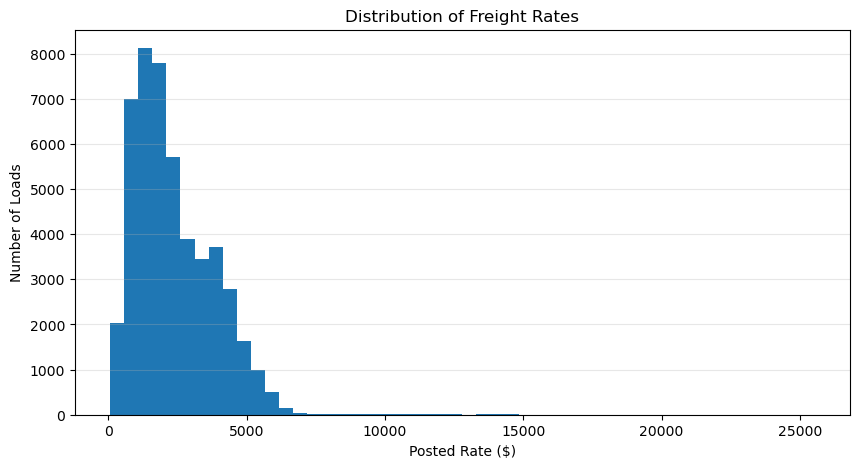

In [40]:
plt.figure(figsize=(10, 5))

plt.hist(data["posted_rate"].dropna(), bins=50)

plt.title("Distribution of Freight Rates")
plt.xlabel("Posted Rate ($)")
plt.ylabel("Number of Loads")

plt.grid(axis="y", alpha=0.3)
plt.show()

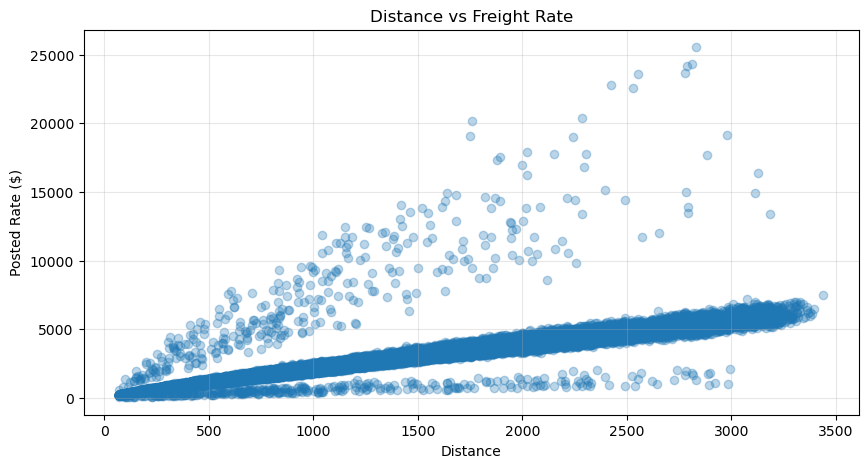

In [41]:
plt.figure(figsize=(10, 5))

plt.scatter(
    data["distance"],
    data["posted_rate"],
    alpha=0.3
)

plt.title("Distance vs Freight Rate")
plt.xlabel("Distance")
plt.ylabel("Posted Rate ($)")

plt.grid(alpha=0.3)
plt.show()

In [42]:
equipment_rates = data.groupby("equipment")[
    "posted_rate"
].agg(["count", "mean", "median"])

equipment_rates

,count,mean,median
equipment,,,
Dry Van,27202,2271.548686,1953.035
Flatbed,8753,2445.087223,2076.810
Reefer,12045,2553.636939,2196.670


<Figure size 900x500 with 0 Axes>

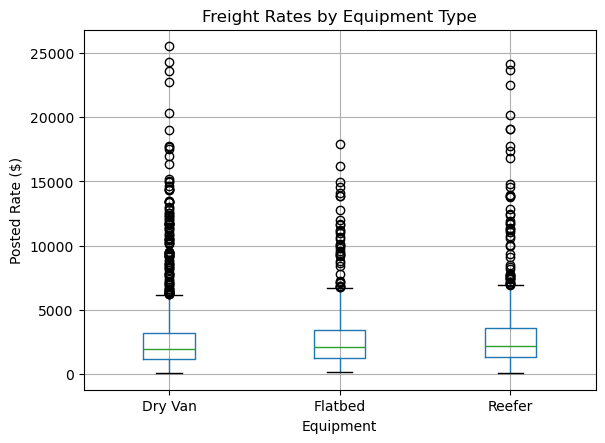

In [43]:
plt.figure(figsize=(9, 5))

data.boxplot(
    column="posted_rate",
    by="equipment"
)

plt.title("Freight Rates by Equipment Type")
plt.suptitle("")
plt.xlabel("Equipment")
plt.ylabel("Posted Rate ($)")

plt.show()

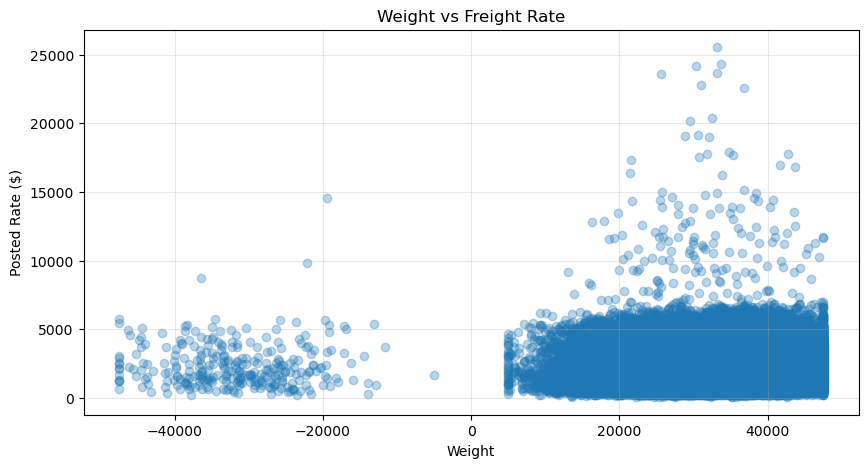

In [44]:
plt.figure(figsize=(10, 5))

plt.scatter(
    data["weight"],
    data["posted_rate"],
    alpha=0.3
)

plt.title("Weight vs Freight Rate")
plt.xlabel("Weight")
plt.ylabel("Posted Rate ($)")

plt.grid(alpha=0.3)
plt.show()

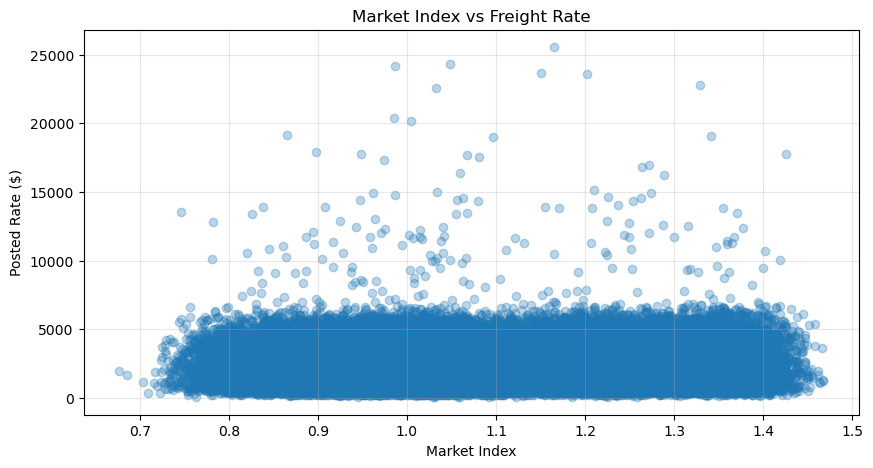

In [45]:
plt.figure(figsize=(10, 5))

plt.scatter(
    data["market_index"],
    data["posted_rate"],
    alpha=0.3
)

plt.title("Market Index vs Freight Rate")
plt.xlabel("Market Index")
plt.ylabel("Posted Rate ($)")

plt.grid(alpha=0.3)
plt.show()

In [46]:
# Create a temporary month column for analysis

data["month"] = data["date"].dt.to_period("M")

monthly_rates = data.groupby("month")[
    "posted_rate"
].mean()

monthly_rates

month
2025-01    2255.967048
2025-02    2273.804801
2025-03    2372.268092
2025-04    2372.162308
2025-05    2421.776342
2025-06    2497.030115
2025-07    2415.162030
2025-08    2338.407661
2025-09    2406.374013
2025-10    2379.051374
Freq: M, Name: posted_rate, dtype: float64

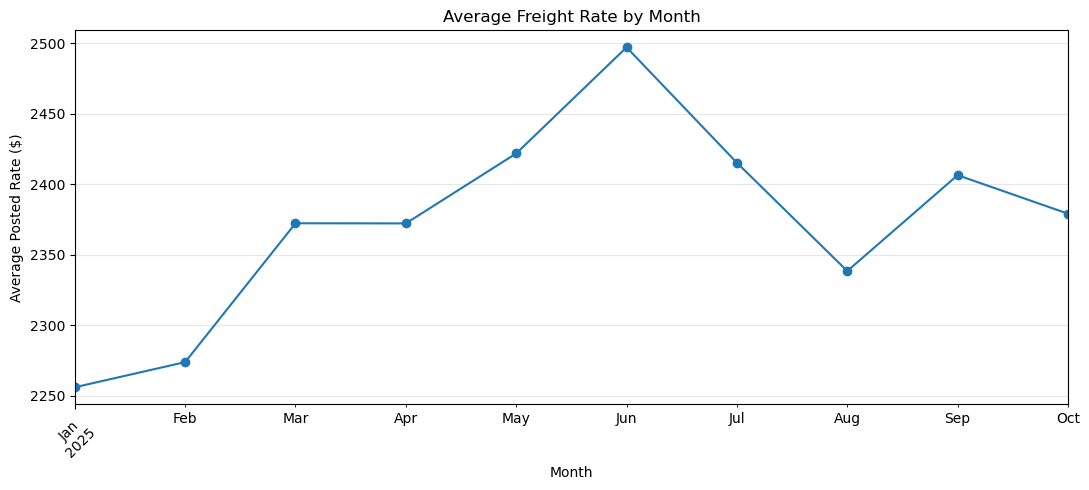

In [47]:
plt.figure(figsize=(11, 5))

monthly_rates.plot(marker="o")

plt.title("Average Freight Rate by Month")
plt.xlabel("Month")
plt.ylabel("Average Posted Rate ($)")

plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [48]:
numerical_data = data.select_dtypes(
    include=np.number
)

correlation = numerical_data.corr()

correlation

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,posted_rate
pickup_lat,1.000000,0.559208,-0.008283,-0.006143,-0.077742,0.001898,-0.001735,-0.004181,-0.090873
pickup_lon,0.559208,1.000000,-0.008609,-0.012231,-0.273411,0.006603,0.001432,0.013659,-0.255058
delivery_lat,-0.008283,-0.008609,1.000000,0.557083,-0.080646,-0.004243,-0.002587,-0.002708,-0.091970
delivery_lon,-0.006143,-0.012231,0.557083,1.000000,-0.275657,-0.001144,-0.008487,0.011437,-0.257086
distance,-0.077742,-0.273411,-0.080646,-0.275657,1.000000,0.002544,-0.002181,-0.057244,0.908519
weight,0.001898,0.006603,-0.004243,-0.001144,0.002544,1.000000,-0.001331,0.008159,0.034840
market_index,-0.001735,0.001432,-0.002587,-0.008487,-0.002181,-0.001331,1.000000,-0.067827,0.034165
quote_signal,-0.004181,0.013659,-0.002708,0.011437,-0.057244,0.008159,-0.067827,1.000000,-0.039858
posted_rate,-0.090873,-0.255058,-0.091970,-0.257086,0.908519,0.034840,0.034165,-0.039858,1.000000


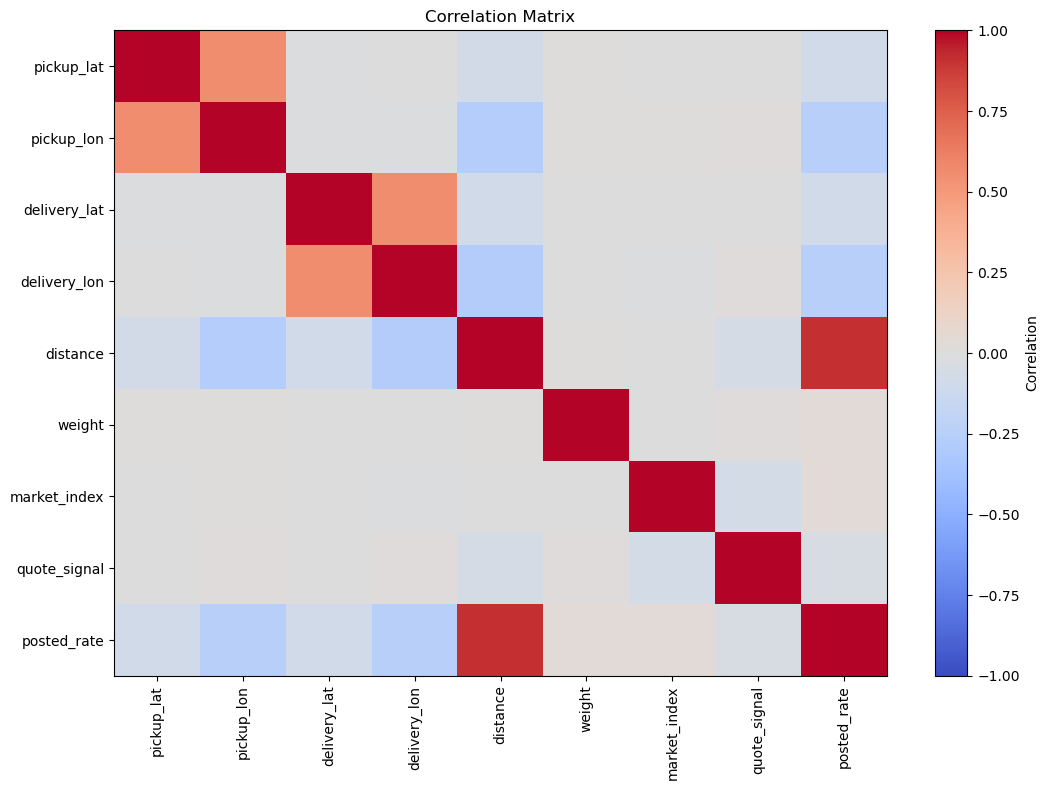

In [49]:
plt.figure(figsize=(11, 8))

plt.imshow(
    correlation,
    cmap="coolwarm",
    aspect="auto",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Matrix")
plt.tight_layout()

plt.show()

In [50]:
# Extract date features

data["year"] = data["date"].dt.year
data["month_num"] = data["date"].dt.month
data["day"] = data["date"].dt.day
data["day_of_week"] = data["date"].dt.dayofweek

data[[
    "date",
    "year",
    "month_num",
    "day",
    "day_of_week",
    "posted_rate"
]].head()

,date,year,month_num,day,day_of_week,posted_rate
0,2025-01-01,2025,1,1,2,645.41
1,2025-01-01,2025,1,1,2,679.97
2,2025-01-01,2025,1,1,2,1802.54
3,2025-01-01,2025,1,1,2,1827.28
4,2025-01-01,2025,1,1,2,1380.28


In [51]:
# Define target variable

target = "posted_rate"

# Separate input features and target

X = data.drop(columns=["posted_rate", "load_id", "date", "month"])
y = data[target]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (48000, 15)
Target shape: (48000,)


In [52]:
# Sort the data by date

data = data.sort_values("date").reset_index(drop=True)

# Training: January to September 2025
train_data = data[
    data["date"] < "2025-10-01"
].copy()

# Validation: October 2025
valid_data = data[
    (data["date"] >= "2025-10-01") &
    (data["date"] < "2025-11-01")
].copy()

print("Training rows:", len(train_data))
print("Validation rows:", len(valid_data))

print(
    "Training date range:",
    train_data["date"].min(),
    "to",
    train_data["date"].max()
)

print(
    "Validation date range:",
    valid_data["date"].min(),
    "to",
    valid_data["date"].max()
)

Training rows: 43147
Validation rows: 4853
Training date range: 2025-01-01 00:00:00 to 2025-09-30 00:00:00
Validation date range: 2025-10-01 00:00:00 to 2025-10-31 00:00:00


In [53]:
# Create training features and target

X_train = train_data.drop(
    columns=["posted_rate", "load_id", "date", "month"]
)

y_train = train_data["posted_rate"]

# Create validation features and target

X_valid = valid_data.drop(
    columns=["posted_rate", "load_id", "date", "month"]
)

y_valid = valid_data["posted_rate"]

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)

X_train: (43147, 15)
X_valid: (4853, 15)
y_train: (43147,)
y_valid: (4853,)


In [54]:
# Identify numerical columns

numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

# Identify categorical columns

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'weight', 'market_index', 'quote_signal', 'year', 'month_num', 'day', 'day_of_week']

Categorical features:
['pickup', 'delivery', 'equipment']


In [55]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [56]:
numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

In [57]:
print("Numerical features:", numerical_features)

Numerical features: ['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'weight', 'market_index', 'quote_signal', 'year', 'month_num', 'day', 'day_of_week']


In [58]:
categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

In [59]:
print("Categorical features:", categorical_features)

Categorical features: ['pickup', 'delivery', 'equipment']


In [60]:
# Numerical preprocessing

numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# Categorical preprocessing

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine both pipelines

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

In [61]:
baseline_model = DummyRegressor(strategy="median")

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_valid)

In [62]:
baseline_mae = mean_absolute_error(
    y_valid, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_valid, baseline_predictions)
)

baseline_r2 = r2_score(
    y_valid, baseline_predictions
)

print("Baseline Model Results")
print("----------------------")
print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))
print("R2:", round(baseline_r2, 4))

Baseline Model Results
----------------------
MAE: 1146.79
RMSE: 1567.97
R2: -0.0522


In [63]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=None,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [64]:
rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['pickup_lat', 'pickup_lon',
                                                   'delivery_lat',
                                                   'delivery_lon', 'distance',
                                                   'weight', 'market_index',
                                                   'quote_signal', 'year',
                                                   'month_num', 'day',
                                                   'day_of_week']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['pickup', 'delivery',
                                                   'equipment'])])),
                ('model',
                 RandomForestRegressor(min_samples_leaf=2, n_estimators=200,
                                       n_jobs=-1, random_state=42))])

In [65]:
rf_predictions = rf_model.predict(X_valid)

In [66]:
rf_mae = mean_absolute_error(
    y_valid, rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(y_valid, rf_predictions)
)

rf_r2 = r2_score(
    y_valid, rf_predictions
)

print("Random Forest Results")
print("---------------------")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2:", round(rf_r2, 4))

Random Forest Results
---------------------
MAE: 148.2
RMSE: 671.19
R2: 0.8072


In [67]:
model_comparison = pd.DataFrame({
    "Model": ["Median Baseline", "Random Forest"],
    "MAE": [baseline_mae, rf_mae],
    "RMSE": [baseline_rmse, rf_rmse],
    "R2": [baseline_r2, rf_r2]
})

model_comparison

,Model,MAE,RMSE,R2
0,Median Baseline,1146.793707,1567.970485,-0.052235
1,Random Forest,148.196798,671.194726,0.807188


In [72]:
# Step 6: Feature preparation for all datasets

# Convert dates to datetime
data["date"] = pd.to_datetime(data["date"], errors="coerce")
validation["date"] = pd.to_datetime(validation["date"], errors="coerce")
december["date"] = pd.to_datetime(december["date"], errors="coerce")

# Select features available in all three datasets
features = [
    "pickup",
    "delivery",
    "distance",
    "equipment",
    "weight"
]

# Create date features for training data
data["year"] = data["date"].dt.year
data["month_num"] = data["date"].dt.month
data["day"] = data["date"].dt.day
data["day_of_week"] = data["date"].dt.dayofweek

# Create the same date features for validation data
validation["year"] = validation["date"].dt.year
validation["month_num"] = validation["date"].dt.month
validation["day"] = validation["date"].dt.day
validation["day_of_week"] = validation["date"].dt.dayofweek

# Create the same date features for December data
december["year"] = december["date"].dt.year
december["month_num"] = december["date"].dt.month
december["day"] = december["date"].dt.day
december["day_of_week"] = december["date"].dt.dayofweek

# Add date features to the common feature list
features += ["year", "month_num", "day", "day_of_week"]

print("Common features:", features)
print("\nTraining shape:", data[features].shape)
print("Validation shape:", validation[features].shape)
print("December shape:", december[features].shape)

Common features: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'year', 'month_num', 'day', 'day_of_week']

Training shape: (48000, 9)
Validation shape: (12000, 9)
December shape: (31, 9)


In [73]:
# Remove rows without a valid date or target
model_data = data.dropna(
    subset=["date", "posted_rate"]
).copy()

# Sort data chronologically
model_data = model_data.sort_values("date").reset_index(drop=True)

# Use the earliest 80% for training and latest 20% for holdout
split_index = int(len(model_data) * 0.80)

train_data = model_data.iloc[:split_index].copy()
holdout_data = model_data.iloc[split_index:].copy()

X_train_common = train_data[features]
y_train_common = train_data["posted_rate"]

X_holdout_common = holdout_data[features]
y_holdout_common = holdout_data["posted_rate"]

print("Training rows:", len(X_train_common))
print("Holdout rows:", len(X_holdout_common))
print("Training dates:", train_data["date"].min(), "to", train_data["date"].max())
print("Holdout dates:", holdout_data["date"].min(), "to", holdout_data["date"].max())

Training rows: 38400
Holdout rows: 9600
Training dates: 2025-01-01 00:00:00 to 2025-08-31 00:00:00
Holdout dates: 2025-08-31 00:00:00 to 2025-10-31 00:00:00


In [74]:
# Identify numerical and categorical columns
numerical_features = X_train_common.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train_common.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Preprocessing pipelines
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_common = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Train Random Forest using only common features
rf_common = Pipeline([
    ("preprocessor", preprocessor_common),
    ("model", RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_common.fit(X_train_common, y_train_common)

# Predict on the holdout data
holdout_predictions = rf_common.predict(X_holdout_common)

# Calculate evaluation metrics
common_mae = mean_absolute_error(
    y_holdout_common, holdout_predictions
)

common_rmse = np.sqrt(mean_squared_error(
    y_holdout_common, holdout_predictions
))

common_r2 = r2_score(
    y_holdout_common, holdout_predictions
)

print("Common-Feature Random Forest Results")
print("------------------------------------")
print(f"MAE:  {common_mae:.2f}")
print(f"RMSE: {common_rmse:.2f}")
print(f"R2:   {common_r2:.4f}")

Common-Feature Random Forest Results
------------------------------------
MAE:  158.79
RMSE: 662.08
R2:   0.8115


In [75]:
from sklearn.model_selection import ParameterGrid

# Small, practical hyperparameter search
param_grid = {
    "model__n_estimators": [200, 300],
    "model__max_depth": [None, 20],
    "model__min_samples_leaf": [2, 5]
}

tuning_results = []

for params in ParameterGrid(param_grid):
    candidate_model = Pipeline([
        ("preprocessor", preprocessor_common),
        ("model", RandomForestRegressor(
            random_state=42,
            n_jobs=-1
        ))
    ])

    candidate_model.set_params(**params)
    candidate_model.fit(X_train_common, y_train_common)

    predictions = candidate_model.predict(X_holdout_common)

    tuning_results.append({
        "parameters": params,
        "MAE": mean_absolute_error(y_holdout_common, predictions),
        "RMSE": np.sqrt(mean_squared_error(
            y_holdout_common, predictions
        )),
        "R2": r2_score(y_holdout_common, predictions)
    })

tuning_results_df = pd.DataFrame(tuning_results)
tuning_results_df = tuning_results_df.sort_values("MAE")

tuning_results_df

,parameters,MAE,RMSE,R2
7,"{'model__max_depth': 20, 'model__min_samples_l...",143.144507,639.791127,0.824004
3,"{'model__max_depth': None, 'model__min_samples...",143.157152,639.796812,0.824000
6,"{'model__max_depth': 20, 'model__min_samples_l...",143.623216,640.049618,0.823861
2,"{'model__max_depth': None, 'model__min_samples...",143.654957,640.069805,0.823850
1,"{'model__max_depth': None, 'model__min_samples...",158.391144,661.808459,0.811682
5,"{'model__max_depth': 20, 'model__min_samples_l...",158.540855,662.294555,0.811405
0,"{'model__max_depth': None, 'model__min_samples...",158.792720,662.082474,0.811526
4,"{'model__max_depth': 20, 'model__min_samples_l...",159.074103,662.727902,0.811158


In [76]:
# Step 8: Train the best tuned Random Forest model

best_model = Pipeline([
    ("preprocessor", preprocessor_common),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=20,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Train on the training portion
best_model.fit(X_train_common, y_train_common)

# Evaluate on the same chronological holdout
best_predictions = best_model.predict(X_holdout_common)

best_mae = mean_absolute_error(
    y_holdout_common, best_predictions
)
best_rmse = np.sqrt(mean_squared_error(
    y_holdout_common, best_predictions
))
best_r2 = r2_score(
    y_holdout_common, best_predictions
)

print("Best Tuned Random Forest Results")
print("--------------------------------")
print(f"MAE:  {best_mae:.2f}")
print(f"RMSE: {best_rmse:.2f}")
print(f"R2:   {best_r2:.4f}")

Best Tuned Random Forest Results
--------------------------------
MAE:  143.14
RMSE: 639.79
R2:   0.8240


In [77]:
# Step 9: Train the final model on all training data

# Prepare all training rows with valid dates and target values
final_train_data = data.dropna(
    subset=["date", "posted_rate"]
).copy()

# Sort training data by date
final_train_data = final_train_data.sort_values("date")

# Select the common features and target
X_final = final_train_data[features]
y_final = final_train_data["posted_rate"]

# Create a fresh model with the selected best parameters
final_model = Pipeline([
    ("preprocessor", preprocessor_common),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=20,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Train using all available training data
final_model.fit(X_final, y_final)

print("Final model training completed.")
print("Training rows:", len(X_final))
print("Number of features:", len(features))

Final model training completed.
Training rows: 48000
Number of features: 9


In [78]:
# Step 10: Generate predictions

# Prepare validation features
X_validation = validation[features].copy()

# Prepare December features
X_december = december[features].copy()

# Generate predictions
validation_predictions = final_model.predict(X_validation)
december_predictions = final_model.predict(X_december)

# Check prediction counts
print("Validation predictions:", len(validation_predictions))
print("December predictions:", len(december_predictions))

# Check for invalid predictions
print(
    "Invalid validation predictions:",
    (~np.isfinite(validation_predictions) | (validation_predictions <= 0)).sum()
)

print(
    "Invalid December predictions:",
    (~np.isfinite(december_predictions) | (december_predictions <= 0)).sum()
)

# Display sample predictions
print("\nValidation prediction samples:")
print(validation_predictions[:10])

print("\nDecember prediction samples:")
print(december_predictions[:10])

Validation predictions: 12000
December predictions: 31
Invalid validation predictions: 0
Invalid December predictions: 0

Validation prediction samples:
[ 851.14736081 5043.23784235 5491.71607811 4008.32624575 1798.71270659
 4461.4553511  5245.5873506  3008.34948462 1146.73775316 1150.09097654]

December prediction samples:
[906.2991767  854.70636734 855.01580163 856.14854395 856.42392501
 855.21232244 848.25870509 853.61010264 854.06350374 850.62415044]


In [80]:
from pathlib import Path
import pandas as pd
import numpy as np

# Create the data directory if it does not exist
data_dir = Path("data")
data_dir.mkdir(parents=True, exist_ok=True)

# Create validation submission using the provided template
submission = template[["load_id"]].copy()
submission["predicted_rate"] = validation_predictions
submission = submission[["load_id", "predicted_rate"]]

# Save validation predictions
submission.to_csv("validation_predictions.csv", index=False)

# Fill and save December predictions
december["predicted_rate"] = december_predictions
december.to_csv(data_dir / "december_chart_inputs.csv", index=False)

print("Files saved successfully.")
print("Current working directory:", Path.cwd())
print("Validation file:", Path("validation_predictions.csv").resolve())
print("December file:", (data_dir / "december_chart_inputs.csv").resolve())
print("Validation shape:", submission.shape)
print("December shape:", december.shape)

Files saved successfully.
Current working directory: C:\Users\shiva kumar
Validation file: C:\Users\shiva kumar\validation_predictions.csv
December file: C:\Users\shiva kumar\data\december_chart_inputs.csv
Validation shape: (12000, 2)
December shape: (31, 11)


In [81]:
from pathlib import Path
import pandas as pd
import numpy as np

# Load the original-format December columns and add predictions
december_output = pd.read_csv("data/december_chart_inputs.csv")

# Keep only the exact columns required by the assessment
required_december_columns = [
    "pickup",
    "delivery",
    "distance",
    "equipment",
    "weight",
    "date",
    "predicted_rate"
]

december_output = december_output[required_december_columns]

# Save with the required column order
december_output.to_csv(
    "data/december_chart_inputs.csv",
    index=False
)

# Reload files to verify saved outputs
saved_submission = pd.read_csv("validation_predictions.csv")
saved_december = pd.read_csv("data/december_chart_inputs.csv")

assert saved_submission.columns.tolist() == [
    "load_id", "predicted_rate"
]
assert len(saved_submission) == 12000
assert saved_submission["load_id"].is_unique
assert saved_submission["predicted_rate"].notna().all()
assert np.isfinite(saved_submission["predicted_rate"]).all()
assert (saved_submission["predicted_rate"] > 0).all()

assert saved_december.columns.tolist() == required_december_columns
assert len(saved_december) == 31
assert saved_december["predicted_rate"].notna().all()
assert np.isfinite(saved_december["predicted_rate"]).all()
assert (saved_december["predicted_rate"] > 0).all()

print("All output-file checks passed.")
print("Validation shape:", saved_submission.shape)
print("December shape:", saved_december.shape)
print("December columns:", saved_december.columns.tolist())

All output-file checks passed.
Validation shape: (12000, 2)
December shape: (31, 7)
December columns: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']


In [84]:
from pathlib import Path

requirements_content = """matplotlib>=3.8,<4
numpy>=1.26,<3
pandas>=2.0,<3
"""

Path("requirements.txt").write_text(
    requirements_content,
    encoding="utf-8"
)

print("requirements.txt created at:")
print(Path("requirements.txt").resolve())

requirements.txt created at:
C:\Users\shiva kumar\requirements.txt


In [85]:
from pathlib import Path

print("Current folder:", Path.cwd())

Current folder: C:\Users\shiva kumar


In [86]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [88]:
from pathlib import Path

score_file = Path.home() / "score.py"

print("File exists:", score_file.exists())
print("File path:", score_file)

File exists: False
File path: C:\Users\shiva kumar\score.py


In [89]:
from pathlib import Path

score_code = r'''from __future__ import annotations

import argparse
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

EXPECTED_ROWS = 12_000
EXPECTED_IDS = {f"TE-{index:06d}" for index in range(1, EXPECTED_ROWS + 1)}
DECEMBER_DATES = pd.date_range("2025-12-01", "2025-12-31", freq="D")
FIXED_PICKUP = "Lexington"
FIXED_DELIVERY = "Fort Wayne"
FIXED_DISTANCE = 360.0
FIXED_EQUIPMENT = "Dry Van"
FIXED_WEIGHT = 32_000.0


def fail(message: str) -> None:
    raise SystemExit(f"ERROR: {message}")


def read_csv(path: Path, label: str) -> pd.DataFrame:
    if not path.is_file():
        fail(f"{label} file not found: {path}")
    try:
        return pd.read_csv(path)
    except Exception as exc:
        fail(f"could not read {label}: {exc}")


def numeric_series(frame: pd.DataFrame, column: str, label: str) -> pd.Series:
    values = pd.to_numeric(frame[column], errors="coerce")
    if values.isna().any() or not np.isfinite(values).all():
        fail(f"{label} contains invalid {column} values")
    return values.astype(float)


def validate_predictions(predictions: pd.DataFrame) -> None:
    if list(predictions.columns) != ["load_id", "predicted_rate"]:
        fail("predictions must contain exactly two columns in this order: load_id,predicted_rate")
    if len(predictions) != EXPECTED_ROWS:
        fail(f"predictions must contain exactly {EXPECTED_ROWS:,} rows")
    if predictions["load_id"].isna().any() or predictions["load_id"].duplicated().any():
        fail("predictions contains missing or duplicate load_id values")

    submitted_ids = set(predictions["load_id"].astype(str))
    missing = EXPECTED_IDS - submitted_ids
    extra = submitted_ids - EXPECTED_IDS
    if missing or extra:
        fail(
            "prediction IDs do not match the validation set "
            f"(missing={len(missing)}, extra={len(extra)})"
        )

    predicted_rate = numeric_series(predictions, "predicted_rate", "predictions")
    if (predicted_rate <= 0).any():
        fail("predictions contains non-positive predicted_rate values")


def validate_december(frame: pd.DataFrame) -> pd.DataFrame:
    columns = ["pickup", "delivery", "distance", "equipment", "weight", "date", "predicted_rate"]
    if list(frame.columns) != columns:
        fail("December predictions must keep the original seven columns and column order")

    result = frame.copy()
    result["date"] = pd.to_datetime(result["date"], errors="coerce")
    if result["date"].isna().any():
        fail("December predictions contains invalid dates")
    result["distance"] = numeric_series(result, "distance", "December predictions")
    result["weight"] = numeric_series(result, "weight", "December predictions")
    result["predicted_rate"] = numeric_series(result, "predicted_rate", "December predictions")

    if result["date"].duplicated().any():
        fail("December predictions contains duplicate dates")
    if len(result) != 31 or set(result["date"]) != set(DECEMBER_DATES):
        fail("December predictions must contain one row for every day from 2025-12-01 to 2025-12-31")
    if not result["pickup"].eq(FIXED_PICKUP).all():
        fail(f"December pickup must be {FIXED_PICKUP} for all rows")
    if not result["delivery"].eq(FIXED_DELIVERY).all():
        fail(f"December delivery must be {FIXED_DELIVERY} for all rows")
    if not np.isclose(result["distance"], FIXED_DISTANCE).all():
        fail(f"December distance must be {FIXED_DISTANCE:g} for all rows")
    if not result["equipment"].eq(FIXED_EQUIPMENT).all():
        fail(f"December equipment must be {FIXED_EQUIPMENT} for all rows")
    if not np.isclose(result["weight"], FIXED_WEIGHT).all():
        fail(f"December weight must be {FIXED_WEIGHT:g} for all rows")
    if (result["predicted_rate"] <= 0).any():
        fail("December predicted_rate values must be positive")
    return result.sort_values("date")


def save_december_chart(december: pd.DataFrame, output: Path) -> None:
    figure, axis = plt.subplots(figsize=(10.8, 4.8), dpi=180)
    color = "#064A56"
    axis.plot(
        december["date"], december["predicted_rate"],
        color=color, linewidth=2.6, marker="o", markersize=3.2,
    )
    floor = float(december["predicted_rate"].min())
    axis.fill_between(
        december["date"], december["predicted_rate"],
        floor - max(10.0, floor * 0.02), color=color, alpha=0.08,
    )
    axis.set_title(
        "Candidate: December 2025 Predicted Load Rate",
        loc="left", fontsize=15, fontweight="bold", pad=12
    )
    axis.set_ylabel("Predicted rate ($)")
    axis.grid(axis="y", color="#D9E2E4", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)
    axis.spines[["left", "bottom"]].set_color("#9DAFB3")
    axis.tick_params(axis="x", rotation=35)
    axis.text(
        0, -0.40,
        "Fixed inputs: Lexington to Fort Wayne | 360 miles | Dry Van | 32,000 lb | only date changes",
        transform=axis.transAxes, fontsize=9.5, color="#455A60",
    )
    figure.tight_layout(rect=(0, 0.12, 1, 1))
    figure.savefig(output, bbox_inches="tight")
    plt.close(figure)


def main() -> None:
    parser = argparse.ArgumentParser(
        description="Validate candidate output files and generate the fixed December chart."
    )
    parser.add_argument("--predictions", required=True, help="CSV with load_id,predicted_rate")
    parser.add_argument(
        "--december-predictions", required=True,
        help="Completed data/december_chart_inputs.csv",
    )
    parser.add_argument("--output-dir", default="scorer_results")
    args = parser.parse_args()

    validate_predictions(read_csv(Path(args.predictions), "predictions"))
    december = validate_december(read_csv(Path(args.december_predictions), "December predictions"))
    output = Path(args.output_dir)
    output.mkdir(parents=True, exist_ok=True)
    chart = output / "candidate_december.png"
    save_december_chart(december, chart)

    print(f"Validated {EXPECTED_ROWS:,} final predictions.")
    print("Validated 31 fixed December predictions.")
    print(f"Created chart: {chart}")
    print("Final validation metrics are calculated by Spotter after submission.")


if __name__ == "__main__":
    main()
'''

score_path = Path.home() / "score.py"
score_path.write_text(score_code, encoding="utf-8")

print("Created:", score_path)
print("File exists:", score_path.exists())
print("File size:", score_path.stat().st_size, "bytes")

Created: C:\Users\shiva kumar\score.py
File exists: True
File size: 6416 bytes


In [90]:
from pathlib import Path

score_path = Path.home() / "score.py"
print("File exists:", score_path.is_file())
print("File path:", score_path.resolve())

File exists: True
File path: C:\Users\shiva kumar\score.py


In [91]:
import subprocess
import sys
from pathlib import Path

home = Path.home()

result = subprocess.run(
    [
        sys.executable,
        str(home / "score.py"),
        "--predictions",
        str(home / "validation_predictions.csv"),
        "--december-predictions",
        str(home / "data" / "december_chart_inputs.csv"),
        "--output-dir",
        str(home / "scorer_results")
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("Errors or warnings:")
    print(result.stderr)

print("Exit code:", result.returncode)

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: C:\Users\shiva kumar\scorer_results\candidate_december.png
Final validation metrics are calculated by Spotter after submission.

Exit code: 0


Chart exists: True


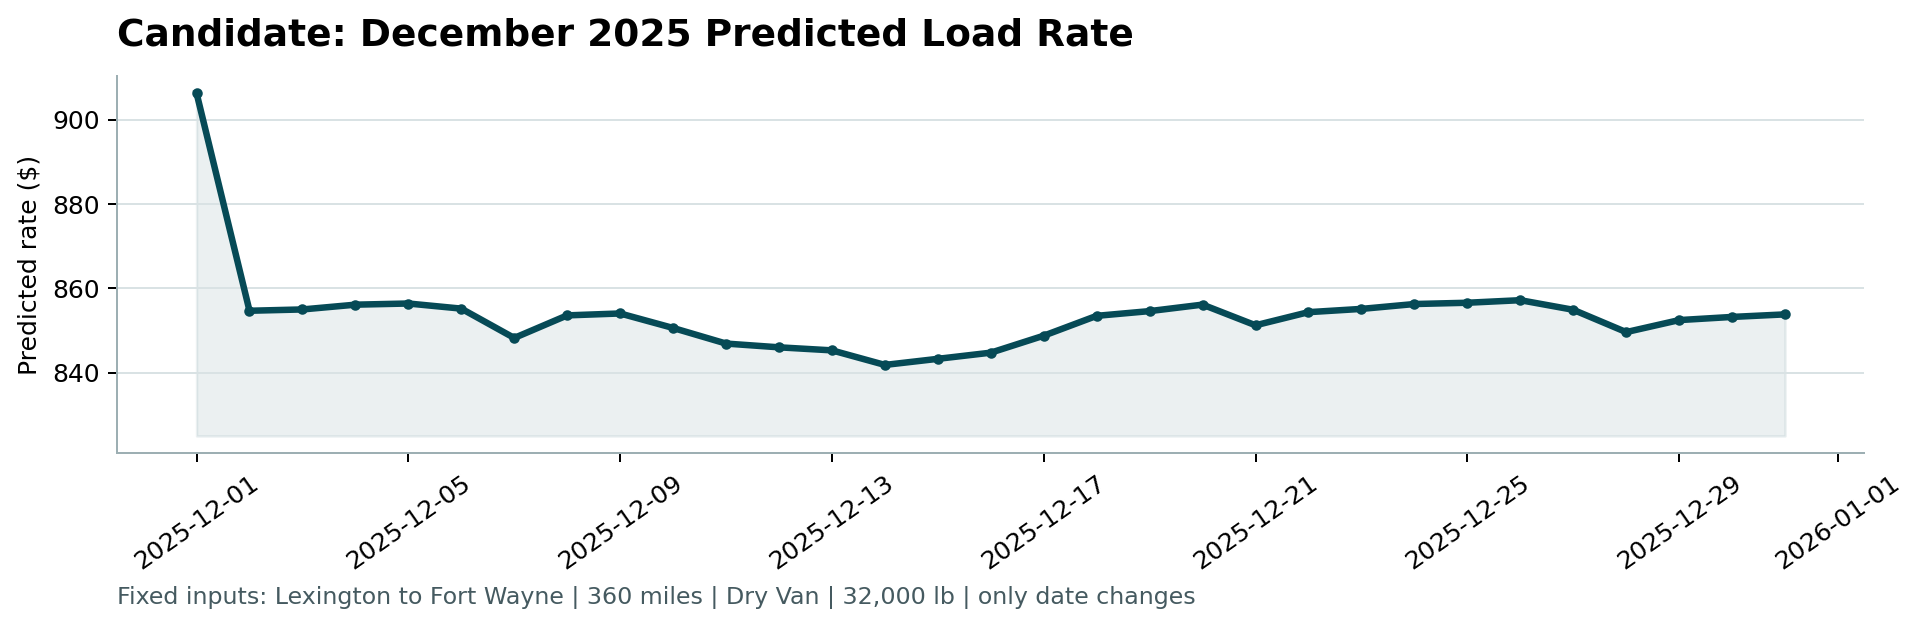

In [92]:
from pathlib import Path
from IPython.display import display, Image

chart_path = Path.home() / "scorer_results" / "candidate_december.png"

print("Chart exists:", chart_path.exists())
display(Image(filename=str(chart_path)))

In [93]:

import joblib
from pathlib import Path

# Save the trained pipeline and its feature names
model_artifact = {
    "model": final_model,
    "features": features
}

model_path = Path.cwd() / "freight_rate_model.pkl"
joblib.dump(model_artifact, model_path)

print("Model saved successfully!")
print("Location:", model_path)
print("File size (MB):", round(model_path.stat().st_size / (1024 * 1024), 2))


Model saved successfully!
Location: C:\Users\shiva kumar\freight_rate_model.pkl
File size (MB): 186.74
